# 01 · Validación del experimento y exploración — Hillstrom E-Mail

**Contexto:** el dataset del *MineThatData E-Mail Analytics Challenge* (Kevin Hillstrom, 2008) tiene 64.000 clientes que compraron en los últimos doce meses. Cada cliente fue asignado al azar a uno de tres grupos: recibió un email con productos para **hombres**, un email con productos para **mujeres**, o **ningún email** (control). Durante las dos semanas siguientes se registró si visitó el sitio (`visit`), si compró (`conversion`) y cuánto gastó (`spend`).

**Objetivo de este notebook:** antes de estimar el efecto de las campañas, comprobar que el experimento está bien hecho y entender los datos. Un A/B test solo permite conclusiones causales si la asignación fue realmente aleatoria, y eso se puede verificar.

**Preguntas que responde este notebook**
1. ¿Los datos están completos y son consistentes?
2. ¿Los tres grupos tienen el tamaño esperado (un tercio cada uno)?
3. ¿Los grupos son comparables en las características previas al experimento?
4. ¿Cómo se comportan las variables resultado (visita, conversión y gasto)?

## Plan de análisis

Se fija antes de mirar los resultados, para no elegir métricas o comparaciones según lo que "salga bien":

- **Comparaciones principales:** email para hombres vs. control, y email para mujeres vs. control. **Comparación secundaria:** email para hombres vs. email para mujeres.
- **Métrica principal:** conversión (si el cliente compró). Es binaria y mide directamente el objetivo de la campaña.
- **Métricas secundarias:** visita al sitio y gasto por cliente. El gasto es la medida del valor para el negocio, pero tiene una distribución muy asimétrica y por eso se analiza con más cuidado.
- **Criterio estadístico:** nivel de significancia de 0,05 (bilateral), con corrección por comparaciones múltiples (Holm, dentro de cada métrica y sobre las tres comparaciones) y reporte de intervalos de confianza junto con los p-valores.
- **Análisis por segmentos:** exploratorio. Sirve para generar hipótesis, no para confirmarlas.

## 1. Setup

Se importan las librerías y las funciones de carga de datos de `src/data.py`. El notebook asume la estructura del repositorio (las carpetas `notebooks/` y `src/` dentro de la misma carpeta raíz), por eso se agrega la carpeta superior al `sys.path`.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import load_hillstrom, prepare, GRUPOS

plt.rcParams["figure.dpi"] = 110

## 2. Carga de datos

`load_hillstrom()` lee el CSV de `data/raw/` o lo descarga desde el blog de MineThatData la primera vez. `prepare()` valida que estén las columnas esperadas y agrega la columna `grupo` con nombres cortos: `control`, `hombres` y `mujeres`.

In [2]:
raw = load_hillstrom()
df = prepare(raw)
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (64000, 13)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,grupo
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0,mujeres
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,control
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0,mujeres
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,hombres
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,mujeres


## 3. Calidad de los datos

Se revisan los tipos de datos, los valores nulos, los rangos de las variables y que los indicadores binarios solo contengan 0 y 1. Como el dataset no trae un identificador de cliente, no se pueden verificar duplicados: dos filas iguales pueden ser clientes distintos con las mismas características.

In [3]:
print("Valores nulos en total:", int(df.isna().sum().sum()))
print()
print(df.dtypes)

Valores nulos en total: 0

recency               int64
history_segment         str
history             float64
mens                  int64
womens                int64
zip_code                str
newbie                int64
channel                 str
segment                 str
visit                 int64
conversion            int64
spend               float64
grupo              category
dtype: object


In [4]:
binarias = ["mens", "womens", "newbie", "visit", "conversion"]
for c in binarias:
    valores = sorted(df[c].unique().tolist())
    assert set(valores) <= {0, 1}, f"{c} tiene valores fuera de 0/1: {valores}"
print("Las variables binarias contienen solo 0 y 1.")
print()
df[["recency", "history", "spend"]].describe().round(2)

Las variables binarias contienen solo 0 y 1.



,recency,history,spend
count,64000.00,64000.00,64000.00
mean,5.76,242.09,1.05
std,3.51,256.16,15.04
min,1.00,29.99,0.00
25%,2.00,64.66,0.00
50%,6.00,158.11,0.00
75%,9.00,325.66,0.00
max,12.00,3345.93,499.00


### 3.1 Consistencia entre las variables resultado

Visitar el sitio, comprar y gastar están relacionados: no debería haber gasto sin compra, y una compra sin visita previa sería un caso raro. El desafío original pide justamente señalar anomalías, así que se cuentan estos casos.

In [5]:
inconsistencias = pd.Series({
    "compra sin visita (conversion=1, visit=0)": int(((df.conversion == 1) & (df.visit == 0)).sum()),
    "gasto sin compra (spend>0, conversion=0)": int(((df.spend > 0) & (df.conversion == 0)).sum()),
    "compra sin gasto (conversion=1, spend=0)": int(((df.conversion == 1) & (df.spend == 0)).sum()),
})
inconsistencias.to_frame("filas")

,filas
"compra sin visita (conversion=1, visit=0)",0
"gasto sin compra (spend>0, conversion=0)",0
"compra sin gasto (conversion=1, spend=0)",0


## 4. Validación de la aleatorización

### 4.1 Tamaño de los grupos (Sample Ratio Mismatch)

Si la asignación fue 1/3 a cada grupo, los tamaños observados deberían ser cercanos a un tercio del total. Una desviación grande (*sample ratio mismatch*) indicaría un problema en la asignación o en el registro de los datos, y volvería sospechosas todas las conclusiones. Se compara con una prueba chi-cuadrado de bondad de ajuste.

In [6]:
conteo = df["grupo"].value_counts().reindex(GRUPOS)
esperado = np.full(len(GRUPOS), len(df) / len(GRUPOS))
chi2, p_srm = stats.chisquare(conteo.values, esperado)

tabla = pd.DataFrame({
    "clientes": conteo,
    "proporción": conteo / len(df),
    "esperados": esperado.round(1),
})
print(f"Chi-cuadrado = {chi2:.3f} | p = {p_srm:.4f}")
tabla.round(4)

Chi-cuadrado = 0.203 | p = 0.9037


,clientes,proporción,esperados
grupo,,,
control,21306,0.3329,21333.3
hombres,21307,0.3329,21333.3
mujeres,21387,0.3342,21333.3


### 4.2 Balance de las características previas

Si la asignación fue aleatoria, las características medidas **antes** del experimento (recencia, historial de compras, zona, canal, etc.) deberían distribuirse de forma parecida en los tres grupos. Se evalúa con pruebas de hipótesis (chi-cuadrado para variables categóricas, ANOVA y Kruskal-Wallis para las numéricas) y con la **diferencia estandarizada de medias** (SMD) respecto del control, que no depende del tamaño de la muestra. Una regla habitual es considerar problemática una SMD mayor a 0,1.

Con varias pruebas a la vez, es esperable que alguna dé p < 0,05 solo por azar: con 8 variables evaluadas y sin ninguna diferencia real, la probabilidad de que al menos una resulte "significativa" es de aproximadamente 34 %.

In [7]:
categoricas = ["history_segment", "zip_code", "channel", "newbie", "mens", "womens"]
filas = []
for c in categoricas:
    tab = pd.crosstab(df["grupo"], df[c])
    chi2, p, gl, _ = stats.chi2_contingency(tab)
    n = tab.values.sum()
    v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    filas.append({"variable": c, "prueba": "chi-cuadrado", "estadístico": chi2, "p_valor": p, "tamaño_efecto": v})

for c in ["recency", "history"]:
    grupos = [df.loc[df.grupo == g, c] for g in GRUPOS]
    f, p_a = stats.f_oneway(*grupos)
    h, p_k = stats.kruskal(*grupos)
    filas.append({"variable": c, "prueba": "ANOVA", "estadístico": f, "p_valor": p_a, "tamaño_efecto": np.nan})
    filas.append({"variable": c, "prueba": "Kruskal-Wallis", "estadístico": h, "p_valor": p_k, "tamaño_efecto": np.nan})

balance = pd.DataFrame(filas)
print("tamaño_efecto = V de Cramér (solo para chi-cuadrado)")
balance.round(4)

tamaño_efecto = V de Cramér (solo para chi-cuadrado)


,variable,prueba,estadístico,p_valor,tamaño_efecto
0,history_segment,chi-cuadrado,13.1533,0.3580,0.0101
1,zip_code,chi-cuadrado,2.8719,0.5795,0.0047
2,channel,chi-cuadrado,3.6324,0.4580,0.0053
3,newbie,chi-cuadrado,0.1369,0.9339,0.0015
4,mens,chi-cuadrado,0.7960,0.6717,0.0035
5,womens,chi-cuadrado,0.6325,0.7289,0.0031
6,recency,ANOVA,0.2704,0.7631,NaN
7,recency,Kruskal-Wallis,0.4611,0.7941,NaN
8,history,ANOVA,0.3595,0.6980,NaN
9,history,Kruskal-Wallis,0.8102,0.6669,NaN


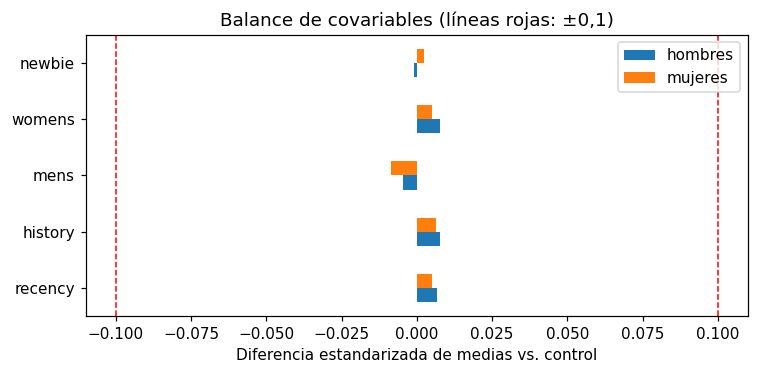

,hombres,mujeres
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026


In [8]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

vars_smd = ["recency", "history", "mens", "womens", "newbie"]
control = df[df.grupo == "control"]
smd_tab = pd.DataFrame({
    g: [smd(df.loc[df.grupo == g, c], control[c]) for c in vars_smd]
    for g in ["hombres", "mujeres"]
}, index=vars_smd)

ax = smd_tab.plot.barh(figsize=(7, 3.5))
ax.axvline(0.1, color="red", linestyle="--", linewidth=1)
ax.axvline(-0.1, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Diferencia estandarizada de medias vs. control")
ax.set_title("Balance de covariables (líneas rojas: ±0,1)")
plt.tight_layout()
plt.show()

smd_tab.round(4)

## 5. Variables resultado (descripción, todavía sin inferencia)

Se describen las tres variables resultado. Esta sección **no** estima ni contrasta el efecto de las campañas: eso se hace en el notebook 02, con los intervalos de confianza y las correcciones del plan de análisis.

In [9]:
resumen = df.groupby("grupo", observed=True).agg(
    clientes=("visit", "size"),
    tasa_visita=("visit", "mean"),
    tasa_conversion=("conversion", "mean"),
    gasto_medio=("spend", "mean"),
)
resumen.round(4)

,clientes,tasa_visita,tasa_conversion,gasto_medio
grupo,,,,
control,21306,0.1062,0.0057,0.6528
hombres,21307,0.1828,0.0125,1.4226
mujeres,21387,0.1514,0.0088,1.0772


### 5.1 El gasto: muchos ceros y una cola larga

Como la conversión es poco frecuente, la gran mayoría de los clientes tiene gasto cero, y entre quienes compraron hay pocos montos muy altos. Esa distribución (asimétrica y con exceso de ceros) afecta la elección de los métodos del notebook 02: con muchos ceros y una cola larga, los intervalos basados en la normalidad podrían no ser confiables, por lo que se contrastan con un bootstrap.

Clientes con gasto cero: 99.1%
Clientes con gasto positivo: 578

Gasto entre quienes gastaron:
count    578.00
mean     116.36
std      107.87
min       29.99
50%       80.80
90%      256.49
99%      499.00
max      499.00
Name: spend, dtype: float64


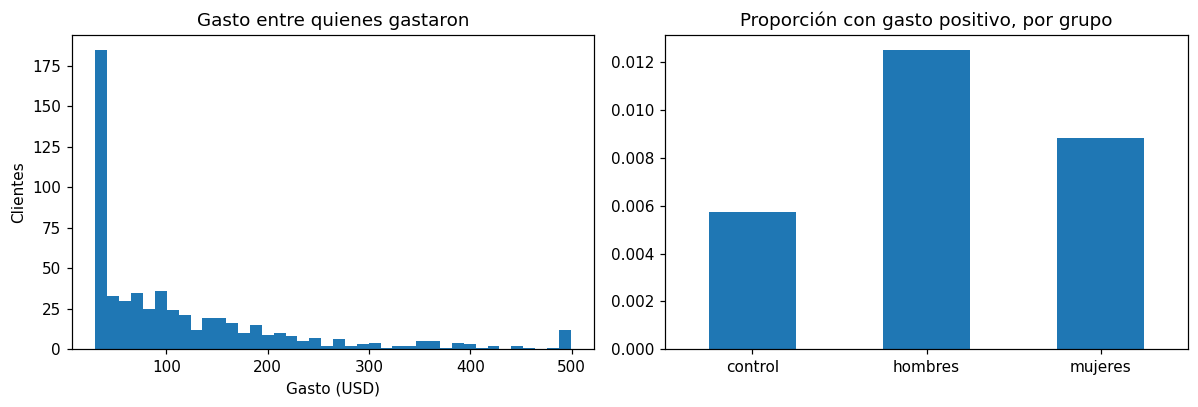

In [10]:
pct_cero = (df["spend"] == 0).mean()
compradores = df[df["spend"] > 0]["spend"]
print(f"Clientes con gasto cero: {pct_cero:.1%}")
print(f"Clientes con gasto positivo: {len(compradores):,}")
print()
print("Gasto entre quienes gastaron:")
print(compradores.describe(percentiles=[0.5, 0.9, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(compradores, bins=40)
axes[0].set_title("Gasto entre quienes gastaron")
axes[0].set_xlabel("Gasto (USD)")
axes[0].set_ylabel("Clientes")

(df["spend"] > 0).groupby(df["grupo"], observed=True).mean().plot.bar(ax=axes[1])
axes[1].set_title("Proporción con gasto positivo, por grupo")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 6. Conclusiones

- **Calidad de los datos:** 64.000 clientes y 13 columnas (las 12 originales más `grupo`), sin valores nulos y con las variables binarias solo en 0 y 1. No hay inconsistencias entre las variables resultado: no existe gasto sin compra, compra sin gasto ni compra sin visita.
- **Tamaño de los grupos:** 21.306 clientes en control, 21.307 con el email para hombres y 21.387 con el email para mujeres. La prueba chi-cuadrado (p = 0,90) no detecta desviación respecto de un tercio por grupo, así que no hay sample ratio mismatch.
- **Balance de las características previas:** los p-valores de las 10 pruebas van de 0,36 a 0,93, la V de Cramér es 0,010 o menor y la diferencia estandarizada de medias máxima es 0,009 (el umbral de alerta es 0,1). No hay evidencia de desbalance, lo que es consistente con una aleatorización correcta y permite atribuir al email las diferencias posteriores. Un p-valor alto no prueba que los grupos sean idénticos, solo que no se detecta diferencia.
- **Variables resultado (descripción):** la tasa de visita es 10,6 % en el control, 18,3 % con el email para hombres y 15,1 % con el de mujeres; la conversión, 0,57 %, 1,25 % y 0,88 %; y el gasto medio por cliente, 0,65, 1,42 y 1,08 dólares. Estas diferencias se evalúan formalmente en el notebook 02.
- **Distribución del gasto:** el 99,1 % de los clientes no gastó nada y solo 578 (0,9 %) compraron. Entre ellos, la media es 116,36 dólares y la mediana 80,80, por lo que la distribución es asimétrica con cola derecha. El percentil 99 y el máximo coinciden en 499,00, lo que sugiere que varios clientes tienen exactamente ese monto y podría reflejar un tope en el registro del dato (no verificado). En el notebook 02 se comprueba que el resultado no depende de los montos altos.
- **Implicaciones para el análisis:** la conversión es un evento raro (0,9 %), lo que limita la potencia para detectar diferencias pequeñas, y el gasto, por sus ceros y su cola larga, se analiza además con métodos que no suponen normalidad, como el bootstrap.
- **Limitaciones:** no hay identificador de cliente, por lo que no se pudieron verificar duplicados; el seguimiento cubre solo dos semanas; el experimento incluye únicamente clientes que compraron en los últimos 12 meses, por lo que los resultados no se extienden a clientes nuevos o inactivos; y no hay datos de costos de la campaña.
- **Próximo paso:** el notebook 02 estima el efecto de cada campaña sobre la conversión, la visita y el gasto, con intervalos de confianza y corrección por comparaciones múltiples.